# LAB 02 — Python for Machine Learning & Data Manipulation

**Module:** Python for Machine Learning & Data Manipulation
**Session:** 02
**Duration:** 150 minutes (10-minute break included)
**Audience:** Başlangıç seviyesi Python / Machine Learning katılımcıları

## Bu LAB'ın Sonunda Yapabilecekleriniz

1. Python veri bilimi ekosisteminin temel bileşenlerini tanımak.
2. NumPy array işlemleri gerçekleştirmek.
3. Pandas Series ve DataFrame yapılarını kullanmak.
4. CSV dosyalarını okuyup incelemek.
5. Filtering, Selection ve Sorting uygulamak.
6. GroupBy ve Aggregation kullanmak.
7. Birden fazla ilişkisel tabloyu Merge ve Join ile birleştirmek.
8. Matplotlib ile temel veri görselleştirmeleri oluşturmak.
9. Notebook ile tekrar kullanılabilir Python modülleri arasındaki farkı anlamak.

## Kullanılan Veri Kümeleri

Bu LAB'da **iki farklı ve birbiriyle ilişkisiz** veri kaynağı kullanılır:

| Dataset | Konum | Kullanım Alanı |
|---|---|---|
| **A — E-Commerce Shipping** | `data/ecommerce_shipping/Train.csv` | NumPy, Pandas, Filtering, Sorting, GroupBy, Aggregation, Matplotlib |
| **B — Northwind (customers, orders, shippers)** | `data/northwind/*.csv` | Relational Data, Merge, Join, Join Validation |

Bu iki veri kümesi birbirine **merge/join edilmez** — her biri kendi bölümünde, kendi öğretim amacı için kullanılır.

> **Not:** Veri dosyaları bu notebook tarafından otomatik olarak indirilmez. Her iki veri kümesinin de
> `data/` klasörü altında önceden yerleştirilmiş olması gerekir. Dosya bulunamazsa ilgili hücre açık bir
> `FileNotFoundError` ile duracaktır.


---
## Section 1 — Environment & Python Data Science Ecosystem
**Süre: 10 dakika**

### Learning Objective

Bu bölümde, LAB boyunca kullanacağımız araçları ve çalışma ortamını tanıyacağız.

### Concept Explanation

- **NumPy**: Sayısal diziler (array) üzerinde hızlı, vectorized matematiksel işlemler sağlar.
- **Pandas**: Tablo biçimli veriyi (Series / DataFrame) okuma, filtreleme, gruplama ve birleştirme için kullanılır.
- **Matplotlib**: Verilerin grafiklerle görselleştirilmesini sağlar.
- **Scikit-learn**: Bu LAB'da kullanılmayacak, ancak projede kurulu olan Machine Learning kütüphanesidir
  (modelleme konuları ileriki oturumlarda ele alınacaktır).
- **Jupyter Notebook / JupyterLab**: Kod, açıklama ve çıktıyı aynı dosyada (`.ipynb`) birleştiren interaktif
  bir çalışma ortamıdır. JupyterLab, bu notebook'ların çalıştırıldığı tarayıcı tabanlı arayüzdür.
- **Notebook Cells**: Bir notebook, **Markdown Cells** (açıklama metni, bu hücre gibi) ve **Code Cells**
  (çalıştırılabilir Python kodu) olmak üzere iki tür hücreden oluşur.
- **Kernel**: Code Cells'i çalıştıran arka plandaki Python sürecidir. Kernel, tüm notebook boyunca
  değişkenleri hafızada tutar; bu yüzden hücreler **sırayla** çalıştırılmalıdır.
- **Docker ve JupyterLab İlişkisi**: Bu proje, JupyterLab'ı bir Docker container'ı içinde çalıştırır.
  Böylece her katılımcı, işletim sisteminden bağımsız olarak **aynı Python sürümü ve aynı kütüphane
  sürümleriyle** çalışır — "benim bilgisayarımda çalışıyordu" problemi ortadan kalkar.
- **Python Environment**: Bu projede bağımlılıklar `uv` ile yönetilir; `pyproject.toml` ve `uv.lock`
  dosyaları, kurulu paketlerin tam olarak hangi sürümler olduğunu sabitler (reproducibility).

### Hands-On


In [1]:
# Show the active Python version, kernel working directory, and library versions.
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

print("Python version:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Kernel working directory:", Path.cwd())
print()
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Matplotlib version:", matplotlib.__version__)


Python version: 3.11.18
Platform: Linux-6.18.33.1-microsoft-standard-WSL2-x86_64-with-glibc2.41
Kernel working directory: /app/labs/lab02

NumPy version: 2.4.6
Pandas version: 3.1.0
Matplotlib version: 3.11.2


### Output Interpretation

- `Python version` satırı, kernel'in Docker container içindeki Python 3.11 ortamını kullandığını doğrular.
- `Kernel working directory`, bu notebook dosyasının bulunduğu klasördür — veri dosyalarına erişirken bu
  bilgiyi dikkate almamız gerekir (bir sonraki hücrede bunu `pathlib` ile platform-bağımsız şekilde çözeceğiz).
- Kütüphane sürümleri, `uv.lock` tarafından sabitlenen sürümlerle eşleşmelidir.


In [2]:
# Resolve the project root independently of the current working directory,
# by walking up until pyproject.toml is found. This keeps all paths in this
# notebook platform-independent (no hardcoded Windows absolute paths).
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("Project root:", PROJECT_ROOT)


Project root: /app


### Reusable Configuration Loading

Dosya yollarını notebook içine sabit (hardcoded) yazmak yerine, `src/data_loading.py` içindeki küçük
yardımcı fonksiyonları kullanarak `config/settings.yaml` dosyasını okuyacağız. Bu modülün amacı
`Section 8`'de daha ayrıntılı ele alınacaktır.


In [3]:
from data_loading import load_config

config = load_config()
config


{'project_name': 'ml-labs',
 'random_seed': 42,
 'dataset_dir': 'data',
 'lab_dir': 'labs',
 'log_level': 'INFO',
 'data': {'ecommerce_shipping': 'data/ecommerce_shipping/Train.csv',
  'northwind': {'customers': 'data/northwind/customers.csv',
   'orders': 'data/northwind/orders.csv',
   'shippers': 'data/northwind/shippers.csv'}}}

---
## Section 2 — NumPy Fundamentals
**Süre: 15 dakika**

### Learning Objective

NumPy `ndarray` yapısını tanımak; array oluşturma, indeksleme, vectorized işlemler ve temel istatistikleri
uygulamak.

### Concept Explanation

- **ndarray**: NumPy'ın temel veri yapısıdır; tek tip veriden (örneğin hepsi `int` veya hepsi `float`)
  oluşan, sabit boyutlu bir dizidir.
- **Array Creation**: Bir Python listesinden, bir Pandas sütunundan veya doğrudan NumPy fonksiyonlarından
  (`np.array`, `np.zeros`, `np.arange` gibi) oluşturulabilir.
- **Shape ve Dimensions**: `array.shape`, dizinin her boyuttaki eleman sayısını verir; `array.ndim`,
  boyut sayısını (1D, 2D, ...) verir.
- **Data Types (`dtype`)**: Bir array'deki tüm elemanlar aynı veri tipindedir (örn. `int64`, `float64`).
  Bu, NumPy'ın hızının önemli bir nedenidir.
- **Indexing ve Slicing**: Python listelerine benzer şekilde `array[0]`, `array[1:5]` gibi erişimler yapılır.
- **Vectorized Operations**: Bir döngü yazmadan, tüm array üzerinde aynı işlemi aynı anda uygulamaktır
  (örn. `array / 1000`).
- **Basic Statistical Operations**: `min`, `max`, `mean`, `median`, `std` gibi özet istatistikler.

Bu bölümde **Dataset A (E-Commerce Shipping)** kullanılacaktır.

### Hands-On


In [4]:
from data_loading import load_ecommerce_shipping

# Load the dataset once here; Section 3 will explore it in depth with Pandas.
df = load_ecommerce_shipping(config)
print("Dataset shape:", df.shape)


Dataset shape: (10999, 12)


In [5]:
# Convert two numeric columns to NumPy arrays.
weights = df["Weight_in_gms"].to_numpy()
costs = df["Cost_of_the_Product"].to_numpy()

print("weights -> dtype:", weights.dtype, "shape:", weights.shape, "ndim:", weights.ndim)
print("costs   -> dtype:", costs.dtype, "shape:", costs.shape, "ndim:", costs.ndim)


weights -> dtype: int64 shape: (10999,) ndim: 1
costs   -> dtype: int64 shape: (10999,) ndim: 1


In [6]:
# Basic statistical operations on the weight array.
print("Weight (gms) summary:")
print("  min   :", weights.min())
print("  max   :", weights.max())
print("  mean  :", weights.mean())
print("  median:", np.median(weights))
print("  std   :", weights.std())


Weight (gms) summary:
  min   : 1001
  max   : 7846
  mean  : 3634.016728793527
  median: 4149.0
  std   : 1635.3029076240832


In [7]:
# Boolean masking: shipments heavier than the average weight.
heavy_mask = weights > weights.mean()

print("Number of shipments heavier than average:", heavy_mask.sum())
print("Average product cost for heavy shipments:", costs[heavy_mask].mean())
print("Average product cost for all shipments  :", costs.mean())


Number of shipments heavier than average: 6300
Average product cost for heavy shipments: 203.85650793650794
Average product cost for all shipments  : 210.19683607600692


In [8]:
# Vectorized arithmetic vs. a classic Python loop, on the same data.
import time

sample = weights[:3000]

start = time.perf_counter()
weights_kg_loop = []
for w in sample:
    weights_kg_loop.append(w / 1000)
loop_duration = time.perf_counter() - start

start = time.perf_counter()
weights_kg_vectorized = sample / 1000
vector_duration = time.perf_counter() - start

print(f"Loop duration:       {loop_duration:.6f} s")
print(f"Vectorized duration: {vector_duration:.6f} s")


Loop duration:       0.000566 s
Vectorized duration: 0.000184 s


### Output Interpretation

- `heavy_mask`, her eleman için `True`/`False` değeri tutan bir **boolean array**'dir; `weights[heavy_mask]`
  gibi kullanıldığında yalnızca `True` olan konumlardaki elemanları seçer (Boolean Masking).
- Vectorized işlem, Python seviyesinde bir `for` döngüsü çalıştırmaz; NumPy, işlemi derlenmiş C kodu
  üzerinde toplu olarak yapar. Bu nedenle `sample / 1000` işlemi, aynı sonucu üreten döngüden belirgin
  şekilde daha hızlıdır. Veri büyüdükçe bu fark daha da önemli hale gelir.

### Student Exercise

Aşağıdaki hücreyi kullanarak kendiniz deneyin (şablon yalnızca yorum satırları içerir, bu yüzden
boş haliyle çalıştırıldığında notebook'u bozmaz):


In [9]:
# Student Exercise:
# TODO: Convert the "Discount_offered" column to a NumPy array named `discounts`.
# TODO: Using boolean masking, find how many shipments have a discount greater than 20.
# TODO: Compare the average "Customer_rating" for discounted (>20) vs non-discounted shipments.

# discounts = df["Discount_offered"].to_numpy()
# high_discount_mask = discounts > 20
# ...


---
## Section 3 — Pandas Series, DataFrame & Data Loading
**Süre: 25 dakika**

### Learning Objective

Pandas `Series` ve `DataFrame` yapılarını tanımak; bir CSV dosyasını yükleyip temel keşifsel analiz
(exploratory check) adımlarını uygulamak.

### Concept Explanation

- **Pandas Series**: Tek bir sütunu (etiketli, 1 boyutlu bir diziyi) temsil eder. Bir DataFrame'in her
  sütunu aslında bir Series'tir.
- **Pandas DataFrame**: Satır ve sütunlardan oluşan, Excel tablosuna benzeyen 2 boyutlu veri yapısıdır.
- **`read_csv`**: Bir CSV dosyasını DataFrame'e yükler (bu veriyi Section 2'de zaten `load_ecommerce_shipping`
  ile yüklemiştik).
- **`head()` / `tail()`**: İlk / son N satırı gösterir.
- **`shape`**: (satır sayısı, sütun sayısı) tuple'ı döner.
- **`columns`**: Sütun isimlerini listeler.
- **`dtypes`**: Her sütunun veri tipini gösterir.
- **`info()`**: Sütun sayısı, veri tipleri ve eksik olmayan (non-null) değer sayısını özetler.
- **`describe()`**: Sayısal sütunlar için istatistiksel özet (count, mean, std, min, quartile, max) üretir.
- **`isna()`**: Her hücrenin eksik (`NaN`) olup olmadığını gösterir; `.sum()` ile sütun başına eksik sayısı
  bulunur.
- **`nunique()`**: Bir sütundaki tekil (farklı) değer sayısını verir.
- **`value_counts()`**: Bir sütundaki her değerin kaç kez tekrarlandığını sayar.

### Hands-On

Bu bölümde, Section 2'de yüklenmiş olan `df` (E-Commerce Shipping) DataFrame'i üzerinde çalışılacaktır.


In [10]:
df.head()


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


In [11]:
df.tail()


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
10994,10995,A,Ship,4,1,252,5,medium,F,1,1538,1
10995,10996,B,Ship,4,1,232,5,medium,F,6,1247,0
10996,10997,C,Ship,5,4,242,5,low,F,4,1155,0
10997,10998,F,Ship,5,2,223,6,medium,M,2,1210,0
10998,10999,D,Ship,2,5,155,5,low,F,6,1639,0


In [12]:
print("Shape (rows, columns):", df.shape)
print("Columns:", df.columns.tolist())


Shape (rows, columns): (10999, 12)
Columns: ['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N']


In [13]:
df.dtypes


ID                     int64
Warehouse_block          str
Mode_of_Shipment         str
Customer_care_calls    int64
Customer_rating        int64
Cost_of_the_Product    int64
Prior_purchases        int64
Product_importance       str
Gender                   str
Discount_offered       int64
Weight_in_gms          int64
Reached.on.Time_Y.N    int64
dtype: object

In [14]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   10999 non-null  int64
 1   Warehouse_block      10999 non-null  str  
 2   Mode_of_Shipment     10999 non-null  str  
 3   Customer_care_calls  10999 non-null  int64
 4   Customer_rating      10999 non-null  int64
 5   Cost_of_the_Product  10999 non-null  int64
 6   Prior_purchases      10999 non-null  int64
 7   Product_importance   10999 non-null  str  
 8   Gender               10999 non-null  str  
 9   Discount_offered     10999 non-null  int64
 10  Weight_in_gms        10999 non-null  int64
 11  Reached.on.Time_Y.N  10999 non-null  int64
dtypes: int64(8), str(4)
memory usage: 1.0 MB


In [15]:
df.describe()


,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
count,10999.00000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000
mean,5500.00000,4.054459,2.990545,210.196836,3.567597,13.373216,3634.016729,0.596691
std,3175.28214,1.141490,1.413603,48.063272,1.522860,16.205527,1635.377251,0.490584
min,1.00000,2.000000,1.000000,96.000000,2.000000,1.000000,1001.000000,0.000000
25%,2750.50000,3.000000,2.000000,169.000000,3.000000,4.000000,1839.500000,0.000000
50%,5500.00000,4.000000,3.000000,214.000000,3.000000,7.000000,4149.000000,1.000000
75%,8249.50000,5.000000,4.000000,251.000000,4.000000,10.000000,5050.000000,1.000000
max,10999.00000,7.000000,5.000000,310.000000,10.000000,65.000000,7846.000000,1.000000


> **Not (pandas sürümüne özgü detay):** Bu ortamdaki pandas sürümünde metinsel sütunlar `str` dtype'ı
> ile tutulur (eski pandas sürümlerinde `object` olarak görünürdü). Sayısal ve kategorik sütunları
> ayırırken bu dtype adını kullanacağız.


In [16]:
# Split columns into numerical and categorical groups based on their dtype.
numerical_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(include="string").columns.tolist()

print("Numerical columns  :", numerical_columns)
print("Categorical columns:", categorical_columns)


Numerical columns  : ['ID', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N']
Categorical columns: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


In [17]:
# Missing values per column.
df.isna().sum()


ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64

In [18]:
# Duplicate rows across the whole dataset.
print("Number of fully duplicated rows:", df.duplicated().sum())


Number of fully duplicated rows: 0


In [19]:
# Cardinality (number of unique values) of each categorical column.
for col in categorical_columns:
    print(f"{col}: {df[col].nunique()} unique values -> {sorted(df[col].unique())}")


Warehouse_block: 5 unique values -> ['A', 'B', 'C', 'D', 'F']
Mode_of_Shipment: 3 unique values -> ['Flight', 'Road', 'Ship']
Product_importance: 3 unique values -> ['high', 'low', 'medium']
Gender: 2 unique values -> ['F', 'M']


In [20]:
# Frequency distribution of a few categorical columns.
df["Warehouse_block"].value_counts()


Warehouse_block
F    3666
D    1834
A    1833
B    1833
C    1833
Name: count, dtype: int64

In [21]:
df["Mode_of_Shipment"].value_counts()


Mode_of_Shipment
Ship      7462
Flight    1777
Road      1760
Name: count, dtype: int64

### `Reached.on.Time_Y.N` Kolonunun Anlamı

Bu dataset'in hedef (target) kolonu `Reached.on.Time_Y.N`'dir. Kaggle açıklamasına göre:

- **`1` = Late** (ürün zamanında teslim edilmedi / gecikti)
- **`0` = On Time** (ürün zamanında teslim edildi)

Bu, isminin ima ettiğinin **tersi** bir kodlamadır (`1` "on time" değil, "late" anlamına gelir) — bu
yüzden ileride bu kolonu kullanırken her zaman bu tanımı hatırlamak önemlidir.


In [68]:
# Confirm the column only contains the two expected binary codes.
unique_target_values = sorted(df["Reached.on.Time_Y.N"].unique())
assert unique_target_values == [0, 1], f"Unexpected values: {unique_target_values}"

late_share = df["Reached.on.Time_Y.N"].mean()
print("Unique values in Reached.on.Time_Y.N:", unique_target_values)
print(f"Share of shipments that reached LATE (value=1): {late_share:.2%}")

Unique values in Reached.on.Time_Y.N: [np.int64(0), np.int64(1)]
Share of shipments that reached LATE (value=1): 59.67%


### Output Interpretation

- `info()` çıktısındaki `Non-Null Count` sütunu, `isna().sum()` sonucuyla tutarlı olmalıdır.
- Bu dataset'te eksik değer ve tam satır duplikasyonu bulunmamaktadır (yukarıdaki çıktılarda doğrulandı).
- `Reached.on.Time_Y.N` sütunu yalnızca `0` ve `1` değerlerini içerir; bu da onu bir **binary (ikili)**
  kolon olarak kullanmamızı doğrular.

> Bu aşamada kapsamlı bir **Data Cleaning** işlemi yapılmamaktadır — bu, keşifsel bir incelemedir.

### Student Exercise


In [23]:
# Student Exercise:
# TODO: Find which categorical column has the highest number of unique values.
# TODO: Print the value_counts() of "Product_importance" as percentages (hint: value_counts(normalize=True)).

# df["Product_importance"].value_counts(normalize=True)


---
## Section 4 — Filtering, Selection & Sorting
**Süre: 25 dakika**

### Learning Objective

Belirli sütunları seçmeyi, satırları koşullara göre filtrelemeyi ve DataFrame'i sıralamayı öğrenmek.

### Concept Explanation

- **Column Selection**: `df["col"]` bir Series, `df[["col1", "col2"]]` bir DataFrame döner.
- **`loc`**: Etikete (label) göre satır/sütun seçer; genellikle koşullu filtrelemede kullanılır.
- **`iloc`**: Konuma (integer position) göre satır/sütun seçer.
- **Boolean Indexing**: `df[df["col"] == değer]` şeklinde, koşulu sağlayan satırları seçer.
- **Multiple Conditions**: `&` (ve) ve `|` (veya) operatörleriyle birden fazla koşul birleştirilir; her
  koşul parantez içine alınmalıdır.
- **`isin`**: Bir sütunun değerinin, verilen bir liste içinde olup olmadığını kontrol eder.
- **`query`**: Koşulu, okunabilir bir metin (string) ifadesi olarak yazmayı sağlar.
- **`sort_values`**: DataFrame'i bir veya daha fazla sütuna göre sıralar.
- **`nlargest` / `nsmallest`**: Belirli bir sütuna göre en büyük / en küçük N satırı doğrudan döner
  (sıralamadan daha hızlı ve kısa bir alternatiftir).

### Hands-On


In [24]:
# Column selection.
df[["Warehouse_block", "Mode_of_Shipment", "Cost_of_the_Product"]].head()


,Warehouse_block,Mode_of_Shipment,Cost_of_the_Product
0,D,Flight,177
1,F,Flight,216
2,A,Flight,183
3,B,Flight,176
4,C,Flight,184


In [25]:
# loc: label-based selection with a boolean condition.
df.loc[df["Warehouse_block"] == "F", ["Warehouse_block", "Mode_of_Shipment", "Cost_of_the_Product"]].head()


,Warehouse_block,Mode_of_Shipment,Cost_of_the_Product
1,F,Flight,216
5,F,Flight,162
7,F,Flight,233
11,F,Flight,232
13,F,Flight,275


In [26]:
# iloc: position-based selection (first 5 rows, first 4 columns).
df.iloc[0:5, 0:4]


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls
0,1,D,Flight,4
1,2,F,Flight,4
2,3,A,Flight,2
3,4,B,Flight,3
4,5,C,Flight,2


In [27]:
# Boolean indexing: shipments from a specific warehouse block.
warehouse_f = df[df["Warehouse_block"] == "F"]
print("Shipments from Warehouse_block 'F':", warehouse_f.shape[0])


Shipments from Warehouse_block 'F': 3666


In [28]:
# Comparing the three transport modes (Flight, Road, Ship) by volume.
df["Mode_of_Shipment"].value_counts()


Mode_of_Shipment
Ship      7462
Flight    1777
Road      1760
Name: count, dtype: int64

In [29]:
# isin: shipments sent by ground (Road) or sea (Ship), excluding Flight.
ground_or_sea = df[df["Mode_of_Shipment"].isin(["Road", "Ship"])]
print("Road or Ship shipments:", ground_or_sea.shape[0], "out of", df.shape[0])


Road or Ship shipments: 9222 out of 10999


In [30]:
# High-cost products: above the 75th percentile of Cost_of_the_Product.
cost_threshold = df["Cost_of_the_Product"].quantile(0.75)
high_cost = df[df["Cost_of_the_Product"] > cost_threshold]

print(f"75th percentile cost threshold: {cost_threshold}")
print("High-cost shipments:", high_cost.shape[0])


75th percentile cost threshold: 251.0
High-cost shipments: 2695


In [31]:
# Product_importance categories.
df["Product_importance"].value_counts()


Product_importance
low       5297
medium    4754
high       948
Name: count, dtype: int64

In [70]:
# query: readable string-based filtering.
important_high_rated = df.query("Product_importance == 'high' and Customer_rating >= 4")
important_high_rated[["Product_importance", "Customer_rating", "Cost_of_the_Product"]].head()


,Product_importance,Customer_rating,Cost_of_the_Product
13,high,4,275
18,high,5,239
36,high,5,137
58,high,5,141
64,high,5,261


> **Not:** `Reached.on.Time_Y.N` gibi içinde nokta (`.`) bulunan kolon isimleri, `query()` içinde
> backtick (`` ` ``) ile yazılmalıdır: `` df.query("`Reached.on.Time_Y.N` == 1") ``.


In [72]:
# Multiple conditions combined with & (both must be true).
heavy_and_expensive = df[
    (df["Weight_in_gms"] > df["Weight_in_gms"].quantile(0.75))
    & (df["Cost_of_the_Product"] > df["Cost_of_the_Product"].quantile(0.75)) 
]

print("Heavy AND expensive shipments:", heavy_and_expensive.shape[0])


Heavy AND expensive shipments: 481


In [73]:
# sort_values: heaviest shipments first.
df.sort_values(by="Weight_in_gms", ascending=False)[:10][["ID", "Weight_in_gms", "Mode_of_Shipment"]]


,ID,Weight_in_gms,Mode_of_Shipment
199,200,7846,Ship
245,246,7684,Ship
198,199,7640,Ship
205,206,7588,Ship
213,214,7401,Ship
257,258,6614,Road
251,252,6102,Road
244,245,6064,Ship
8739,8740,6000,Ship
9768,9769,6000,Ship


In [35]:
# nlargest / nsmallest: a shorter alternative to sort_values + head.
print("Top 5 heaviest shipments (nlargest):")
print(df.nlargest(5, "Weight_in_gms")[["ID", "Weight_in_gms"]])

print()
print("Top 5 cheapest products (nsmallest):")
print(df.nsmallest(5, "Cost_of_the_Product")[["ID", "Cost_of_the_Product"]])


Top 5 heaviest shipments (nlargest):
      ID  Weight_in_gms
199  200           7846
245  246           7684
198  199           7640
205  206           7588
213  214           7401

Top 5 cheapest products (nsmallest):
          ID  Cost_of_the_Product
431      432                   96
974      975                   96
2418    2419                   96
5907    5908                   96
10322  10323                   96


### Output Interpretation

- `loc` ve boolean indexing aynı satırları farklı sözdizimiyle seçebilir; `loc` genellikle sütun seçimiyle
  birlikte kullanıldığında daha nettir.
- `isin` birden fazla `==` koşulunu `|` ile birleştirmenin daha kısa bir yoludur.
- Çoklu koşullarda her koşulun parantez içine alınması zorunludur; aksi halde Python operatör önceliği
  hatalı sonuç üretir.
- `nlargest` / `nsmallest`, büyük veri kümelerinde tüm DataFrame'i sıralamadan (`sort_values`) daha
  verimli çalışabilir.

### Student Exercises


In [36]:
# Student Exercise 1:
# TODO: Select shipments from Warehouse_block "A" with Customer_rating == 5.
# TODO: Store the result in a variable named `warehouse_a_top_rated` and show its shape.

# warehouse_a_top_rated = df.loc[(df["Warehouse_block"] == "A") & (df["Customer_rating"] == 5)]


In [37]:
# Student Exercise 2 (query):
# TODO: Using df.query(), select shipments where Mode_of_Shipment == "Flight" and Discount_offered > 10.

# flight_high_discount = df.query("Mode_of_Shipment == 'Flight' and Discount_offered > 10")


---
## Section 5 — GroupBy & Aggregation
**Süre: 25 dakika**

### Learning Objective

Verileri bir veya daha fazla sütuna göre gruplayarak özet istatistikler (aggregation) hesaplamak.

### Concept Explanation

- **`groupby`**: Satırları, belirtilen sütun(lar)daki değerlere göre gruplara ayırır.
- **`count` / `size`**: `count`, her sütun için eksik olmayan değer sayısını verir; `size`, grup başına
  toplam satır sayısını verir (eksik değerden bağımsız).
- **`sum` / `mean` / `median` / `min` / `max`**: Her grup için özet istatistik hesaplar.
- **`agg`**: Aynı anda birden fazla istatistiği ve/veya birden fazla sütunu hesaplamak için kullanılır.
- **Named Aggregations**: `.agg(yeni_isim=("sütun", "fonksiyon"))` sözdizimiyle, sonuç sütunlarına
  anlamlı isimler verilir.
- **`reset_index()`**: `groupby` sonucundaki grup anahtarlarını index'ten normal sütunlara çevirir.
- **Multi-Column Grouping**: Birden fazla sütuna göre aynı anda gruplama yapılabilir (örn. depo VE
  taşıma yöntemi).

### Hands-On

Bu bölümde, depo (`Warehouse_block`) ve taşıma yöntemi (`Mode_of_Shipment`) bazında özet istatistikler
hesaplanacaktır.


In [38]:
# Re-confirm that Reached.on.Time_Y.N is strictly binary before using it as a rate.
assert sorted(df["Reached.on.Time_Y.N"].unique()) == [0, 1]
print("Confirmed: Reached.on.Time_Y.N only contains 0 and 1.")


Confirmed: Reached.on.Time_Y.N only contains 0 and 1.


**Late Delivery Rate nasıl hesaplanır?**

`Reached.on.Time_Y.N` sütununda `1 = Late` olduğu için, bu sütunun **ortalaması (`mean`)**, doğrudan
"gecikme oranını" (late delivery rate) verir. Örneğin ortalama `0.60` ise, grup içindeki gönderilerin
%60'ı geç teslim edilmiştir. Bu, ikili (0/1) bir sütunun ortalamasının, "1" olan satırların oranına eşit
olmasından kaynaklanır.


In [39]:
# Multi-column grouping with named aggregations.
shipment_summary = (
    df.groupby(["Warehouse_block", "Mode_of_Shipment"])
    .agg(
        shipment_count=("ID", "size"),
        avg_product_cost=("Cost_of_the_Product", "mean"),
        avg_weight_in_gms=("Weight_in_gms", "mean"),
        late_delivery_rate=("Reached.on.Time_Y.N", "mean"),
    )
    .reset_index()
)
shipment_summary.head(10)


,Warehouse_block,Mode_of_Shipment,shipment_count,avg_product_cost,avg_weight_in_gms,late_delivery_rate
0,A,Flight,297,210.037037,3660.171717,0.585859
1,A,Road,294,207.268707,3602.901361,0.571429
2,A,Ship,1242,208.818841,3607.724638,0.590177
3,B,Flight,296,210.945946,3601.966216,0.597973
4,B,Road,294,213.312925,3615.602041,0.585034
5,B,Ship,1243,212.175382,3648.488335,0.607401
6,C,Flight,295,210.532203,3625.569492,0.623729
7,C,Road,294,210.938776,3661.574830,0.574830
8,C,Ship,1244,211.407556,3640.284566,0.595659
9,D,Flight,297,210.703704,3672.316498,0.599327


In [40]:
# Collapse to a single grouping column (Mode_of_Shipment) to compare transport modes directly.
mode_summary = (
    df.groupby("Mode_of_Shipment")
    .agg(
        shipment_count=("ID", "size"),
        avg_product_cost=("Cost_of_the_Product", "mean"),
        avg_weight_in_gms=("Weight_in_gms", "mean"),
        late_delivery_rate=("Reached.on.Time_Y.N", "mean"),
    )
    .reset_index()
    .sort_values("late_delivery_rate", ascending=False)
)
mode_summary


,Mode_of_Shipment,shipment_count,avg_product_cost,avg_weight_in_gms,late_delivery_rate
0,Flight,1777,209.306697,3629.378165,0.601576
2,Ship,7462,210.343072,3631.457518,0.597561
1,Road,1760,210.475568,3649.550568,0.588068


### Output Interpretation

- `mode_summary` tablosu, hangi taşıma yönteminin en yüksek gecikme oranına sahip olduğunu `late_delivery_rate`
  sütununa göre azalan sırada gösterir.
- **Önemli:** Bir taşıma yönteminin diğerinden daha yüksek gecikme oranına sahip olması, tek başına bu
  yöntemin gecikmeye **neden olduğu** anlamına gelmez (correlation ≠ causation). Depo konumu, mesafe, sipariş
  hacmi gibi başka faktörler de bu farkı etkileyebilir. Bu veriyle sadece **gözlemlenen bir ilişki** ortaya
  konmaktadır; nedensellik iddiası için ayrı bir analiz (örneğin kontrollü karşılaştırma veya modelleme)
  gerekir.

### Student Exercise


In [41]:
# Student Exercise:
# TODO: Group by "Product_importance" and compute shipment_count, avg_product_cost, and late_delivery_rate.
# TODO: Sort the result by late_delivery_rate in descending order.

# importance_summary = (
#     df.groupby("Product_importance")
#     .agg(...)
#     .reset_index()
#     .sort_values("late_delivery_rate", ascending=False)
# )


---
## Section 6 — Data Merging & Joining — Northwind
**Süre: 20 dakika**

Bu bölümde **E-Commerce Shipping** veri kümesi kullanılmayacaktır. Bundan sonraki tüm örnekler,
ilişkisel veri birleştirme konularını öğretmek amacıyla kullanılan **Northwind** veri kümesi
(`customers`, `orders`, `shippers` tabloları) üzerinden ilerleyecektir.

### Learning Objectives

1. Relational Data (ilişkisel veri) kavramını açıklayabilmek.
2. Primary Key ve Foreign Key arasındaki farkı anlayabilmek.
3. One-to-Many ve Many-to-One ilişkilerini ayırt edebilmek.
4. `pd.merge()` kullanabilmek.
5. `DataFrame.join()` kullanabilmek.
6. Inner Join ile Left Join arasındaki farkı açıklayabilmek.
7. Join sonrasında veri bütünlüğünü (data integrity) kontrol edebilmek.

### 6.1 — Relational Data Fundamentals

- **Relational Tables**: Verinin, tekrarları önlemek amacıyla birbiriyle ilişkili ayrı tablolarda
  tutulmasıdır (örn. müşteri bilgisi her siparişte tekrar yazılmaz; ayrı bir `customers` tablosunda tutulur).
- **Primary Key (PK)**: Bir tablodaki her satırı **tekil** olarak tanımlayan sütun (örn. `CustomerID`,
  `ShipperID`).
- **Foreign Key (FK)**: Bir tablodaki, başka bir tablonun Primary Key'ine referans veren sütun (örn.
  `Orders.CustomerID`, `Orders.ShipVia`).
- **One-to-Many**: Bir müşterinin birden fazla siparişi olabilir (1 customer → N orders).
- **Many-to-One**: Birden fazla sipariş, aynı müşteriye ait olabilir (N orders → 1 customer) — bu,
  One-to-Many ilişkisinin diğer taraftan bakılmış hâlidir.
- **Join Keys**: Birleştirme işleminde kullanılan sütunlar (örn. `CustomerID`, `ShipVia` / `ShipperID`).
- **Join Cardinality**: Birleştirilen tablolar arasındaki ilişkinin türü (`one-to-one`, `one-to-many`,
  `many-to-one`, `many-to-many`). Pandas'ta `validate` parametresiyle bu kontrol edilebilir.

Northwind üzerindeki ilişkiler (yalnızca kavramsal bağlantıları gösterir):

```text
Customers
    |
    | CustomerID
    |
    v
  Orders
    |
    | ShipVia
    |
    v
 Shippers
```

- Bir **müşterinin** birden fazla siparişi olabilir (One-to-Many: Customers → Orders).
- Bir **sipariş** tek bir müşteriye bağlıdır (Many-to-One: Orders → Customers).
- Bir **taşıma şirketi** birden fazla siparişi taşıyabilir (One-to-Many: Shippers → Orders).
- Bir **sipariş** tek bir taşıma şirketine referans verir (Many-to-One: Orders → Shippers).

### 6.2 — Loading Northwind Tables


In [42]:
from data_loading import require_file

northwind_paths = config["data"]["northwind"]

customers_df = pd.read_csv(require_file(PROJECT_ROOT / northwind_paths["customers"]))
orders_df = pd.read_csv(require_file(PROJECT_ROOT / northwind_paths["orders"]))
shippers_df = pd.read_csv(require_file(PROJECT_ROOT / northwind_paths["shippers"]))

for name, frame in [("customers_df", customers_df), ("orders_df", orders_df), ("shippers_df", shippers_df)]:
    print(f"{name}: shape={frame.shape}")


customers_df: shape=(93, 11)
orders_df: shape=(830, 14)
shippers_df: shape=(3, 3)


In [43]:
print("customers_df columns:", customers_df.columns.tolist())
print("orders_df columns   :", orders_df.columns.tolist())
print("shippers_df columns :", shippers_df.columns.tolist())


customers_df columns: ['CustomerID', 'CompanyName', 'ContactName', 'ContactTitle', 'Address', 'City', 'Region', 'PostalCode', 'Country', 'Phone', 'Fax']
orders_df columns   : ['OrderID', 'CustomerID', 'EmployeeID', 'OrderDate', 'RequiredDate', 'ShippedDate', 'ShipVia', 'Freight', 'ShipName', 'ShipAddress', 'ShipCity', 'ShipRegion', 'ShipPostalCode', 'ShipCountry']
shippers_df columns : ['ShipperID', 'CompanyName', 'Phone']


In [44]:
print("customers_df dtypes:")
print(customers_df.dtypes)
print()
print("orders_df dtypes:")
print(orders_df.dtypes)
print()
print("shippers_df dtypes:")
print(shippers_df.dtypes)


customers_df dtypes:
CustomerID      str
CompanyName     str
ContactName     str
ContactTitle    str
Address         str
City            str
Region          str
PostalCode      str
Country         str
Phone           str
Fax             str
dtype: object

orders_df dtypes:
OrderID             int64
CustomerID            str
EmployeeID          int64
OrderDate             str
RequiredDate          str
ShippedDate           str
ShipVia             int64
Freight           float64
ShipName              str
ShipAddress           str
ShipCity              str
ShipRegion            str
ShipPostalCode        str
ShipCountry           str
dtype: object

shippers_df dtypes:
ShipperID      int64
CompanyName      str
Phone            str
dtype: object


In [45]:
# Primary Key uniqueness checks.
print("customers_df['CustomerID'] is unique:", customers_df["CustomerID"].is_unique)
print("shippers_df['ShipperID'] is unique  :", shippers_df["ShipperID"].is_unique)


customers_df['CustomerID'] is unique: True
shippers_df['ShipperID'] is unique  : True


In [46]:
# Foreign Key null checks (null join keys cannot be matched).
print("orders_df['CustomerID'] nulls:", orders_df["CustomerID"].isna().sum())
print("orders_df['ShipVia'] nulls   :", orders_df["ShipVia"].isna().sum())


orders_df['CustomerID'] nulls: 0
orders_df['ShipVia'] nulls   : 0


### Output Interpretation

- `CustomerID` (customers) ve `ShipperID` (shippers) tekil (unique) olduğu için bu sütunlar birer
  Primary Key'dir ve merge işleminde `validate="many_to_one"` kullanmamıza izin verir.
- `orders_df` içindeki `CustomerID` ve `ShipVia` sütunlarında null değer bulunmaması, bu Foreign Key'lerin
  tüm siparişler için eşleştirilebilir olduğunu gösterir.

### 6.3 — Merge Example 1: Orders + Customers

**Amaç:** Her siparişin hangi müşteriye ait olduğunu göstermek.

Join keys: `orders_df.CustomerID` ↔ `customers_df.CustomerID`


In [47]:
rows_before = len(orders_df)

orders_customers = pd.merge(
    orders_df,
    customers_df,
    on="CustomerID",
    how="left",
    validate="many_to_one",
)

rows_after = len(orders_customers)
print("orders_df rows        :", rows_before)
print("orders_customers rows :", rows_after)
print("Rows preserved        :", rows_before == rows_after)


orders_df rows        : 830
orders_customers rows : 830
Rows preserved        : True


In [48]:
orders_customers[["OrderID", "CustomerID", "CompanyName", "Country"]].head()


,OrderID,CustomerID,CompanyName,Country
0,10248,VINET,Vins et alcools Chevalier,France
1,10249,TOMSP,Toms Spezialitten,Germany
2,10250,HANAR,Hanari Carnes,Brazil
3,10251,VICTE,Victuailles en stock,France
4,10252,SUPRD,Suprmes dlices,Belgium


### Explain

- **Why Left Join?** `orders_df` taraf olarak sabit tutulur; her siparişin bir sonucu olmalıdır, eşleşen
  müşteri bulunamasa bile sipariş satırı kaybolmamalıdır.
- **What is Many-to-One?** Her sipariş (many) tam olarak bir müşteriye (one) karşılık gelir. Bu LAB'da
  bu ilişki doğrulanmıştır (bkz. `customers_df['CustomerID'].is_unique == True`).
- **Why validate the relationship?** `validate="many_to_one"` parametresi, `customers_df` tarafında
  `CustomerID` değerinin tekrarlanmadığını pandas'a doğrulatır; aksi halde pandas bir `MergeError` fırlatır.
  Bu, sessizce yanlış (satır çoğalmış) bir sonuç almamızı önler.
- **What happens when an order has no matching customer?** `how="left"` sayesinde sipariş satırı
  kaybolmaz; eşleşmeyen müşteri sütunları (`CompanyName`, `Country` vb.) `NaN` olarak doldurulur.
- **Why should row counts be checked?** Satır sayısının merge öncesi/sonrası aynı kalması (`rows_before
  == rows_after`), beklenmedik bir satır çoğalmasının (fan-out) olmadığını doğrulamanın en basit yoludur.

Bu veri kümesinde her sipariş gerçek bir müşteriyle eşleştiği için (`orders_df['CustomerID']` içindeki
tüm değerler `customers_df` içinde bulunur), satır sayısı değişmemiştir.

### 6.4 — Merge Example 2: Orders + Shippers

**Amaç:** Siparişlerin hangi taşıma şirketiyle ilişkilendirildiğini göstermek.

Join keys: `orders_df.ShipVia` ↔ `shippers_df.ShipperID` (sütun isimleri farklı olduğu için `left_on` /
`right_on` kullanılır).


In [49]:
orders_with_shippers = pd.merge(
    orders_df,
    shippers_df,
    left_on="ShipVia",
    right_on="ShipperID",
    how="left",
    validate="many_to_one",
)

print("orders_df rows           :", len(orders_df))
print("orders_with_shippers rows:", len(orders_with_shippers))


orders_df rows           : 830
orders_with_shippers rows: 830


In [50]:
orders_with_shippers[["OrderID", "CustomerID", "ShipVia", "CompanyName", "Freight"]].head()


,OrderID,CustomerID,ShipVia,CompanyName,Freight
0,10248,VINET,3,Federal Shipping,32.38
1,10249,TOMSP,1,Speedy Express,11.61
2,10250,HANAR,2,United Package,65.83
3,10251,VICTE,1,Speedy Express,41.34
4,10252,SUPRD,2,United Package,51.30


Bu örnekte `orders_df` ve `shippers_df` arasında çakışan sütun ismi bulunmadığı için `suffixes`
parametresine ihtiyaç yoktu. Çakışan isimler olduğunda (örn. her iki tabloda da `CompanyName` varsa),
pandas bunları otomatik olarak `_x` / `_y` ile ayırır — `suffixes` parametresiyle bu son eklerin ismini
biz belirleyebiliriz. Bunu bir sonraki örnekte (6.5) göreceğiz.

### 6.5 — Merge Example 3: Three-Table Join

Üç tabloyu sırayla birleştireceğiz: **Orders + Customers + Shippers**.


In [51]:
orders_full = pd.merge(
    orders_df,
    customers_df,
    on="CustomerID",
    how="left",
    validate="many_to_one",
)

# customers_df and shippers_df both have "CompanyName" and "Phone" columns,
# so this second merge needs suffixes to tell them apart.
orders_full = pd.merge(
    orders_full,
    shippers_df,
    left_on="ShipVia",
    right_on="ShipperID",
    how="left",
    validate="many_to_one",
    suffixes=("_customer", "_shipper"),
)

print("orders_df rows   :", len(orders_df))
print("orders_full rows :", len(orders_full))
print("Rows preserved   :", len(orders_df) == len(orders_full))


orders_df rows   : 830
orders_full rows : 830
Rows preserved   : True


In [52]:
order_summary = orders_full[
    ["OrderID", "CompanyName_customer", "OrderDate", "CompanyName_shipper", "ShippedDate", "Freight"]
].rename(
    columns={
        "CompanyName_customer": "Customer",
        "CompanyName_shipper": "Shipper",
    }
)
order_summary.head()


,OrderID,Customer,OrderDate,Shipper,ShippedDate,Freight
0,10248,Vins et alcools Chevalier,1996-07-04 00:00:00,Federal Shipping,1996-07-16 00:00:00,32.38
1,10249,Toms Spezialitten,1996-07-05 00:00:00,Speedy Express,1996-07-10 00:00:00,11.61
2,10250,Hanari Carnes,1996-07-08 00:00:00,United Package,1996-07-12 00:00:00,65.83
3,10251,Victuailles en stock,1996-07-08 00:00:00,Speedy Express,1996-07-15 00:00:00,41.34
4,10252,Suprmes dlices,1996-07-09 00:00:00,United Package,1996-07-11 00:00:00,51.30


### Output Interpretation

- İki `validate="many_to_one"` merge'ü art arda uyguladığımız ve her ikisi de hatasız tamamlandığı için,
  satır sayısının `orders_df` ile aynı kalması (`len(orders_df) == len(orders_full)`) beklenen ve
  doğrulanan bir sonuçtur.
- Beklenmeyen bir satır artışı görülseydi, bu genellikle "one" tarafındaki anahtarın (örn. `CustomerID`)
  aslında tekil olmadığı anlamına gelirdi — ki bu durumda `validate="many_to_one"` zaten bir hata
  fırlatarak bizi uyarırdı.

### 6.6 — `DataFrame.join()`

`pd.merge()` iki ayrı DataFrame'i sütun bazında birleştirir; `DataFrame.join()` ise genellikle bir
DataFrame'in **index**'i ile diğerinin bir sütununu (veya index'ini) eşleştirir. `shippers_df`'i
`ShipperID` üzerinden index'leyip `orders_df` ile `join()` ile birleştirelim:


In [53]:
shippers_indexed = shippers_df.set_index("ShipperID")

orders_joined = orders_df.join(shippers_indexed, on="ShipVia", suffixes=("", "_shipper"))

print("orders_with_shippers (merge) rows:", len(orders_with_shippers))
print("orders_joined (join) rows        :", len(orders_joined))
print("Same row count:", len(orders_with_shippers) == len(orders_joined))


orders_with_shippers (merge) rows: 830
orders_joined (join) rows        : 830
Same row count: True


In [54]:
orders_joined[["OrderID", "ShipVia", "CompanyName", "Freight"]].head()


,OrderID,ShipVia,CompanyName,Freight
0,10248,3,Federal Shipping,32.38
1,10249,1,Speedy Express,11.61
2,10250,2,United Package,65.83
3,10251,1,Speedy Express,41.34
4,10252,2,United Package,51.30


### 6.7 — Join Integrity & Validation

Her join işleminden önce ve sonra kontrol edilmesi gereken noktalar:


In [55]:
# Row count before / after (already shown above, repeated here for the Orders + Customers merge).
print("Row count before join (orders_df):", len(orders_df))
print("Row count after join (orders_customers):", len(orders_customers))


Row count before join (orders_df): 830
Row count after join (orders_customers): 830


In [56]:
# Missing join keys.
print("Missing CustomerID in orders_df:", orders_df["CustomerID"].isna().sum())
print("Missing ShipVia in orders_df   :", orders_df["ShipVia"].isna().sum())

# Duplicate join keys on the "one" side of the relationship.
print("Duplicate CustomerID in customers_df:", customers_df["CustomerID"].duplicated().sum())
print("Duplicate ShipperID in shippers_df  :", shippers_df["ShipperID"].duplicated().sum())


Missing CustomerID in orders_df: 0
Missing ShipVia in orders_df   : 0
Duplicate CustomerID in customers_df: 0
Duplicate ShipperID in shippers_df  : 0


In [57]:
# Unmatched records, made visible with indicator=True.
merge_check = pd.merge(orders_df, customers_df, on="CustomerID", how="left", indicator=True)
merge_check["_merge"].value_counts()


_merge
both          830
left_only       0
right_only      0
Name: count, dtype: int64

- **`validate="many_to_one"`**: Merge'den önce, sağ taraftaki (veya belirtilen taraftaki) join key'in
  tekil olup olmadığını kontrol eder; değilse `MergeError` fırlatır.
- **`indicator=True`**: Sonuç DataFrame'ine `_merge` adında bir sütun ekler; bu sütun her satırın
  `"both"` (eşleşti), `"left_only"` (sadece sol tarafta var) veya `"right_only"` (sadece sağ tarafta var)
  olduğunu gösterir. Bu, eşleşmeyen kayıtları açıkça görmemizi sağlar.

Bu veri kümesinde tüm siparişler `"both"` olarak işaretlenmiştir — yani her siparişin eşleşen bir
müşterisi vardır.

### Important Technical Notes

- Başarılı şekilde çalışan bir join, sonucun **mutlaka doğru olduğu** anlamına gelmez — yanlış ama
  var olan bir anahtar üzerinden de "başarılı" bir eşleşme elde edilebilir.
- Yanlış join key kullanımı (örn. yanlış sütunu eşleştirmek) ciddi veri kalitesi problemleri oluşturabilir.
- **Many-to-Many** bir join, beklenmedik satır çoğalmasına (fan-out) yol açabilir; bu LAB'daki tüm
  join'ler `many_to_one` olduğu için bu risk yoktur.
- Satır sayısının korunması **tek başına** doğru eşleşmeyi kanıtlamaz; yanlış ama bire-bir eşleşen bir
  anahtar da satır sayısını korur. Satır sayısı kontrolü, sorunları yakalamak için **gerekli ama
  yeterli olmayan** bir adımdır.
- Eşleşmeyen veya null join key içeren kayıtlar ayrıca (örn. `indicator=True` ile) değerlendirilmelidir.
- **Pandas'ın null join key davranışı SQL'den farklı olabilir:** standart SQL'de `NULL = NULL`
  karşılaştırması asla `True` olmaz, bu nedenle null anahtarlar asla eşleşmez. Pandas'ta `merge` ve
  `join` işlemleri, bazı durumlarda `NaN` değerlerini birbirine eşit kabul edip eşleştirebilir. Bu
  davranış farkı, SQL deneyimi olan katılımcılar için şaşırtıcı olabilir ve null key içeren birleştirme
  sonuçlarının her zaman ayrıca kontrol edilmesini gerektirir.

### Student Exercise — Order Freight Analysis by Shipper

**Task:** Northwind `Orders` ve `Shippers` tablolarını birleştirerek taşıma şirketi bazında:

- Total Orders
- Average Freight
- Total Freight

metriklerini oluşturun. Sonuçları `Total Freight` değerine göre azalan sıralayın.


In [58]:
# Student Exercise:
# TODO: Merge orders_df with shippers_df (left_on="ShipVia", right_on="ShipperID").
# TODO: Group by the shipper's CompanyName and compute:
#       - total_orders  (count of orders)
#       - avg_freight   (mean of Freight)
#       - total_freight (sum of Freight)
# TODO: Sort by total_freight in descending order.

# freight_by_shipper = (
#     pd.merge(orders_df, shippers_df, left_on="ShipVia", right_on="ShipperID", how="left")
#     .groupby("CompanyName")
#     .agg(total_orders=("OrderID", "count"), avg_freight=("Freight", "mean"), total_freight=("Freight", "sum"))
#     .reset_index()
#     .sort_values("total_freight", ascending=False)
# )


### Advanced Challenge (opsiyonel — ana ders süresine dahil değildir)

Deneyimli katılımcılar için: `Customers` + `Orders` + `Shippers` tablolarını birleştirerek müşteri
ülkesi (`Country`) ve taşıma şirketi bazında Freight analizi gerçekleştirin.


In [59]:
# Advanced Challenge (optional):
# TODO: Build on `orders_full` from Section 6.5.
# TODO: Group by ["Country", "CompanyName_shipper"] and compute total_freight and avg_freight.
# TODO: Sort by total_freight in descending order.

# country_shipper_freight = (
#     orders_full.groupby(["Country", "CompanyName_shipper"])
#     .agg(total_freight=("Freight", "sum"), avg_freight=("Freight", "mean"))
#     .reset_index()
#     .sort_values("total_freight", ascending=False)
# )


---
## Section 7 — Data Visualization with Matplotlib
**Süre: 15 dakika**

Bu bölümde, **Dataset A (E-Commerce Shipping)** veri kümesine geri dönüyoruz.

### Learning Objective

Matplotlib ile temel grafik türlerini (bar chart, histogram) oluşturmak ve yorumlamak.

### Concept Explanation

- **Figure ve Axes**: `Figure`, tüm çizimi içeren "tuval"dir; `Axes`, üzerine çizim yapılan tek bir
  grafik alanıdır (`fig, ax = plt.subplots()`).
- **Bar Chart**: Kategorik değerleri karşılaştırmak için kullanılır (örn. taşıma yöntemine göre sayım).
- **Histogram**: Sayısal bir değişkenin dağılımını göstermek için kullanılır.
- **Labels ve Titles**: `set_xlabel`, `set_ylabel`, `set_title` ile grafiğin ne anlattığı netleştirilir.
- **Legend**: Birden fazla seri (kategori) aynı grafikte gösterildiğinde hangi rengin neyi temsil ettiğini
  açıklar. Bu bölümdeki grafiklerin her biri tek bir seriden oluştuğu için ayrıca bir legend'a gerek
  yoktur — başlık, grafiğin ne olduğunu zaten açıklar.
- **Figure Size**: `figsize=(genişlik, yükseklik)` ile grafiğin boyutu ayarlanır.
- **Chart Interpretation**: Bir grafiğin doğru okunması, eksen etiketlerinin ve ölçeğin dikkatle
  incelenmesini gerektirir.

### Hands-On

#### Chart 1 — Shipment Count by Transport Mode


In [60]:
import matplotlib.pyplot as plt

BAR_COLOR = "#2a78d6"
GRID_COLOR = "#e1e0d9"


def style_bar_axes(ax):
    # Apply a consistent, minimal style shared by all bar charts in this section.
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)


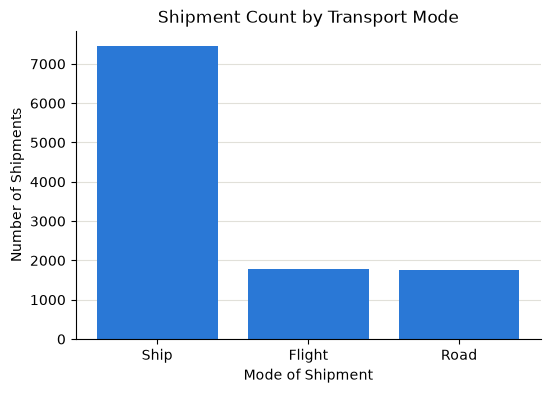

In [61]:
shipment_counts = df["Mode_of_Shipment"].value_counts()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(shipment_counts.index, shipment_counts.values, color=BAR_COLOR)
ax.set_title("Shipment Count by Transport Mode")
ax.set_xlabel("Mode of Shipment")
ax.set_ylabel("Number of Shipments")
style_bar_axes(ax)
plt.show()


#### Chart 2 — Average Product Weight by Warehouse Block


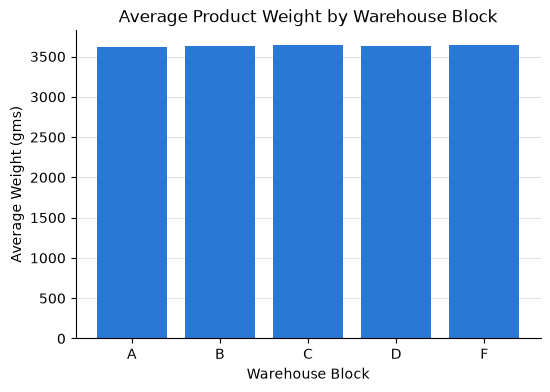

In [62]:
avg_weight_by_block = df.groupby("Warehouse_block")["Weight_in_gms"].mean().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(avg_weight_by_block.index, avg_weight_by_block.values, color=BAR_COLOR)
ax.set_title("Average Product Weight by Warehouse Block")
ax.set_xlabel("Warehouse Block")
ax.set_ylabel("Average Weight (gms)")
style_bar_axes(ax)
plt.show()


#### Chart 3 — Late Delivery Rate by Shipment Mode


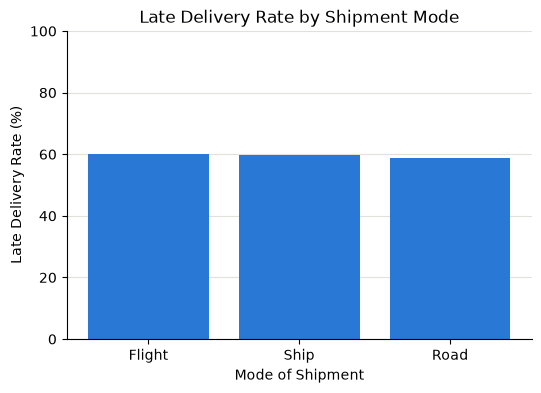

In [63]:
late_rate_by_mode = (
    (df.groupby("Mode_of_Shipment")["Reached.on.Time_Y.N"].mean() * 100)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(late_rate_by_mode.index, late_rate_by_mode.values, color=BAR_COLOR)
ax.set_title("Late Delivery Rate by Shipment Mode")
ax.set_xlabel("Mode of Shipment")
ax.set_ylabel("Late Delivery Rate (%)")
ax.set_ylim(0, 100)
style_bar_axes(ax)
plt.show()


### Output Interpretation

- Grafik 1, hangi taşıma yönteminin veri kümesinde en sık kullanıldığını gösterir.
- Grafik 2, depo bloklarının ortalama ürün ağırlığı açısından birbirine oldukça yakın olup olmadığını
  gösterir — büyük bir fark varsa, bu belirli bir deponun farklı türde ürünler barındırdığına işaret
  edebilir.
- Grafik 3, Section 5'teki `mode_summary` tablosundaki `late_delivery_rate` sütununu görsel olarak
  özetler; sayısal tablo ile grafik aynı sonucu doğrulamalıdır.

> Bu bölümde kasıtlı olarak sade bar chart'lar kullanılmıştır; gereksiz görsel karmaşıklıktan (3D efekt,
> çok fazla renk, dual-axis vb.) kaçınılmıştır.


---
## Section 8 — Code Organization & Exit Challenge
**Süre: 5 dakika**

### Learning Objective

Notebook içinde yazılan kod ile tekrar kullanılabilir bir Python modülü arasındaki farkı anlamak.

### Concept Explanation

- **Notebook vs. Reusable Python Module**: Bir notebook, keşif ve öğretim için idealdir — kod, açıklama
  ve çıktı bir aradadır. Ancak birden fazla notebook'ta tekrar tekrar kullanılacak kod (örneğin "config
  dosyasını oku" veya "bu CSV'yi yükle") notebook içine kopyala-yapıştır yapılırsa bakımı zorlaşır.
- **Functions**: Tekrar eden mantığı tek bir yerde tanımlamanın en basit yoludur.
- **Pathlib**: Dosya yollarını işletim sisteminden bağımsız (Windows / Linux / macOS) şekilde yönetmek
  için kullanılır — bu notebook boyunca `Path` nesneleri kullandık, hiçbir yerde `C:\...` gibi sabit bir
  Windows yolu yazmadık.
- **Configuration**: Dosya yollarını kod içine gömmek yerine `config/settings.yaml` gibi bir dosyada
  tutmak, yolların tek bir yerden yönetilmesini sağlar.
- **Reusable Data Loading**: Bu LAB'da bu fonksiyonları `src/data_loading.py` dosyasında topladık:
  - `get_project_root()` — proje kök dizinini bulur.
  - `load_config()` — `config/settings.yaml`'ı okur.
  - `require_file()` — bir dosyanın var olduğunu doğrular, yoksa açık bir hata verir.
  - `load_ecommerce_shipping()` — E-Commerce Shipping CSV'sini config üzerinden yükler.
- **Separation of Concerns**: Notebook, "ne yapılacağını" (analiz adımları) anlatır; `src/` modülü ise
  "nasıl yapılacağını" (dosya okuma, path çözümleme gibi altyapı detaylarını) saklar.

`src/` klasörünün amacı budur: notebook'ları tekrarlayan altyapı kodundan (boilerplate) kurtarmak. Bu
LAB'da yalnızca gerçekten tekrar kullanılan, küçük fonksiyonlar `src/` içine taşınmıştır — gereksiz class
veya abstraction katmanı eklenmemiştir.

### Exit Challenge

**Görev:** E-Commerce Shipping verisi üzerinde, `Mode_of_Shipment` bazında şu değerleri **tek bir
DataFrame** içinde oluşturun:

- `shipment_count`
- `avg_product_cost`
- `late_delivery_rate`

(İpucu: Bu, Section 5'te yaptığımız `mode_summary` hesaplamasına çok benzer — farkları gözlemleyin.)


In [64]:
# Exit Challenge:
# TODO: Group `df` by "Mode_of_Shipment".
# TODO: Compute shipment_count (size), avg_product_cost (mean of Cost_of_the_Product),
#       and late_delivery_rate (mean of "Reached.on.Time_Y.N") as named aggregations.
# TODO: Store the result in a single DataFrame named `exit_challenge_summary`.

# exit_challenge_summary = (
#     df.groupby("Mode_of_Shipment")
#     .agg(
#         shipment_count=("ID", "size"),
#         avg_product_cost=("Cost_of_the_Product", "mean"),
#         late_delivery_rate=("Reached.on.Time_Y.N", "mean"),
#     )
#     .reset_index()
# )


---
## LAB02 Özeti

Bu LAB'da:

- **Dataset A (E-Commerce Shipping)** üzerinde NumPy, Pandas EDA, Filtering/Sorting, GroupBy/Aggregation
  ve Matplotlib görselleştirmeleri uyguladık.
- **Dataset B (Northwind)** üzerinde Primary/Foreign Key kavramlarını, `pd.merge()`, `DataFrame.join()`
  ve join bütünlük kontrollerini (`validate`, `indicator`) uyguladık.
- Notebook içindeki tekrar eden altyapı kodunu `src/data_loading.py` modülüne taşıyarak Notebook ile
  Reusable Module ayrımını gördük.

Bir sonraki oturumda görüşmek üzere!
